# Analysis of segmented water phase

In [2]:
# modules
import os
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import sys
import json
import socket
import subprocess
import gc

#paths
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_water_GDL_ML/'
elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = os.path.join(toppath, 'processing')
    temppath = '/mnt/SSD_2TB_nvme0n1/Robert/tmp/'
    temppath_2 = '/mpc/homes/fische_r/NAS/tmp'
    training_path = '/mpc/homes/fische_r/NAS/DASCOELY/processing/05_membrane_ML/'
else:
    print('host '+host+' currently not supported')
EC_path = os.path.join(toppath, 'EC_lab_files') 
path_02_4D = os.path.join(toppathSSD, '02_registered_3p1D') #h5 with registered data
path_05_4D = os.path.join(toppathSSD, '05_water_GDL_ML') #h5 with segmented data

# fetch githash
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)


cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)

overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))

In [3]:
px = 2.75E-6

In [4]:
def time_fac(unit):
    if unit == 'min':
        tf = 60
    elif unit == 's':
        tf = 1
    else:
        print(unit+' unknown, assume seconds')
        tf = 1
    return tf

def integrate_interpolated_fun(time, fun, dts):
    integ = np.cumsum(fun(time))*dts
    return integ

In [5]:
# normalize data versus mormalized charg
def get_principal_data(ECdata):
    dims = np.array([ECdata[i].dims['t'] for i in range(len(ECdata))])
    # print(dims)
    I = np.zeros(dims.sum())
    timestamps = I.copy()
    E = I.copy()
    Re = I.copy()
    Im = I.copy()
    # print(len(dims))

    I[:dims[0]] = ECdata[0]['I'].data
    # timestamps[:dims[0]] = ECdata[0]['t'].data
    timestamps[:dims[0]] = ECdata[0]['timestamp (utc)'].data
    E[:dims[0]] = ECdata[0]['$E_{we}$'].data
    Im[:dims[0]] = ECdata[0]['-Im(Z)'].data
    Re[:dims[0]] = ECdata[0]['Re(Z)'].data

    for i in range(1,len(dims)):
        I[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['I'].data
        timestamps[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['timestamp (utc)'].data
        # timestamps[dims[i-1]:dims[i-1]+dims[i]] = ECdata[i]['t'].data +ECdata[i-1]['t'].data.max()
        E[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['$E_{we}$'].data
        Im[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['-Im(Z)'].data
        Re[dims[:i].sum():dims[:i].sum()+dims[i]] = ECdata[i]['Re(Z)'].data
    
    order = timestamps.argsort()
    t0 = timestamps[timestamps>0].min()
    # print(t0)
    I = I[order]
    E = E[order]
    Im = Im[order]
    Re = Re[order]
    timestamps = timestamps[order]
    # print(timestamps[0])
    
#     filter out potential overflow cases
    I = I[E>-5]
    Im = Im[E>-5]
    Re = Re[E>-5]
    timestamps = timestamps[E>-5]
    E = E[E>-5]
    
    time = timestamps - t0
    dt = np.gradient(time)
    Q = np.cumsum(-I*dt)
    return Q, I, E, time, Im, Re, timestamps, t0

In [6]:
def plot_EC_with_annot(sample, unit = 'min',y_txt_frac = 8/8,y_txt_scan = 2/20, tl=None, Atomo=0.1):
    
    tf = time_fac(unit)
    J = -I/Atomo
    #plot the echem data 
    fig, ax = plt.subplots(figsize=(20,8))
    if tl is not None:
        ax.set_xlim(tl[0],tl[1])
    plt.title(sample)
    ax.plot(time/tf, -E, 'k', label='$-E_{we}$')
    ax.set_ylim(1,0.1-(E.min()))
    ax2 = ax.twinx()
    ax2.plot(time/tf, J, 'r', label='-J')
    ax.legend(loc='lower left')
    ax2.legend(loc='lower right')
    ax.set_xlabel('time ['+unit+']')
    ax.set_ylabel('$-E_{we}$ [V]')
    ax2.set_ylabel('-J [$mA\cdot cm^{-2}$]')
    ax2.set_ylim(0,J.max())
    
  
    rel_cues = np.array(overview['cues']['timestamp'].copy())
    comms = np.array(overview['cues']['comment'].copy())
    comms = comms[rel_cues>t0]
    rel_cues = rel_cues[rel_cues>t0]
    comms = comms[rel_cues<t0+time.max()]
    rel_cues = rel_cues[rel_cues<t0+time.max()]
    rel_cues = rel_cues-t0

    # text_y = I.max()+(I.min()-I.max())*y_txt_frac
    text_y = 0.8*J.max() #+(J.min()-J.max())*y_txt_frac
    if len(rel_cues)>0:
        for (cue, comm) in zip(rel_cues,comms):
            ax.axvline(cue/tf)
            plt.annotate(comm, xy=(cue/tf, text_y), rotation=90)

    #mark the scan time steps
    scan_steps = []
    check = sample
    if sample == '3II':
        check = '3b'

    # text_2 = I.max()+(I.min()-I.max())*y_txt_scan  
    text_2 = 0.2*J.max()

    for file in os.listdir(path_02_4D):
        if file.split('_')[1] == sample:
            data = xr.open_dataset(os.path.join(path_02_4D, file))
            steps = data['t_utc'].data-t0
            for (i,ts) in zip( range(len(data['t_utc'])),steps):
                ax.axvline(ts/tf, color='k', alpha=0.3)
                plt.annotate(str(i), xy=(ts/tf, text_2), fontsize=10)
            data.close()
    return fig, ax
        

In [7]:
charge_dict = {}

## sample 4

In [9]:
sample = '4'
##load EC data
ECdata = load_sample_data(sample, overview, EC_path)
Q, I, E, time, Im, Re, timestamps, t0 = get_principal_data(ECdata)
charge_dict[sample] = {'Q': Q, 'I': I, 'E': E, 'time': time, 'Im': Im, 'Re':Re, 'timestamps': timestamps, 't0': t0}

In [18]:
seg_data = xr.open_dataset(os.path.join(path_05_4D, sample, sample+'_water_segmentation.nc'))
# seg_data = xr.open_dataset(os.path.join(path_05_4D, sample, 'ec4415d_final_seg.nc'))

In [19]:
water = (seg_data['segmented']==2)

In [33]:
water.shape

(750, 340, 1916, 71)

In [35]:
#TODO: crop to active area
# 4 
a = 7
b = 730
e = 220
f = 1720

In [36]:
watervolume = water[a:b,:,e:f,:].sum(dim = ('x','y','z'))

In [37]:
watervolumeGDL = water[a:b,230:,e:f,:].sum(dim = ('x','y','z'))

In [38]:
seg_data.close()

In [39]:
file = '02_'+sample+'_registered_3p1D.nc'
imagepath = os.path.join(path_02_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()
t_utc_XTM = data['t_utc'].data
time_XTM = data['time'].data
data.close()

(0.07, 0.11)

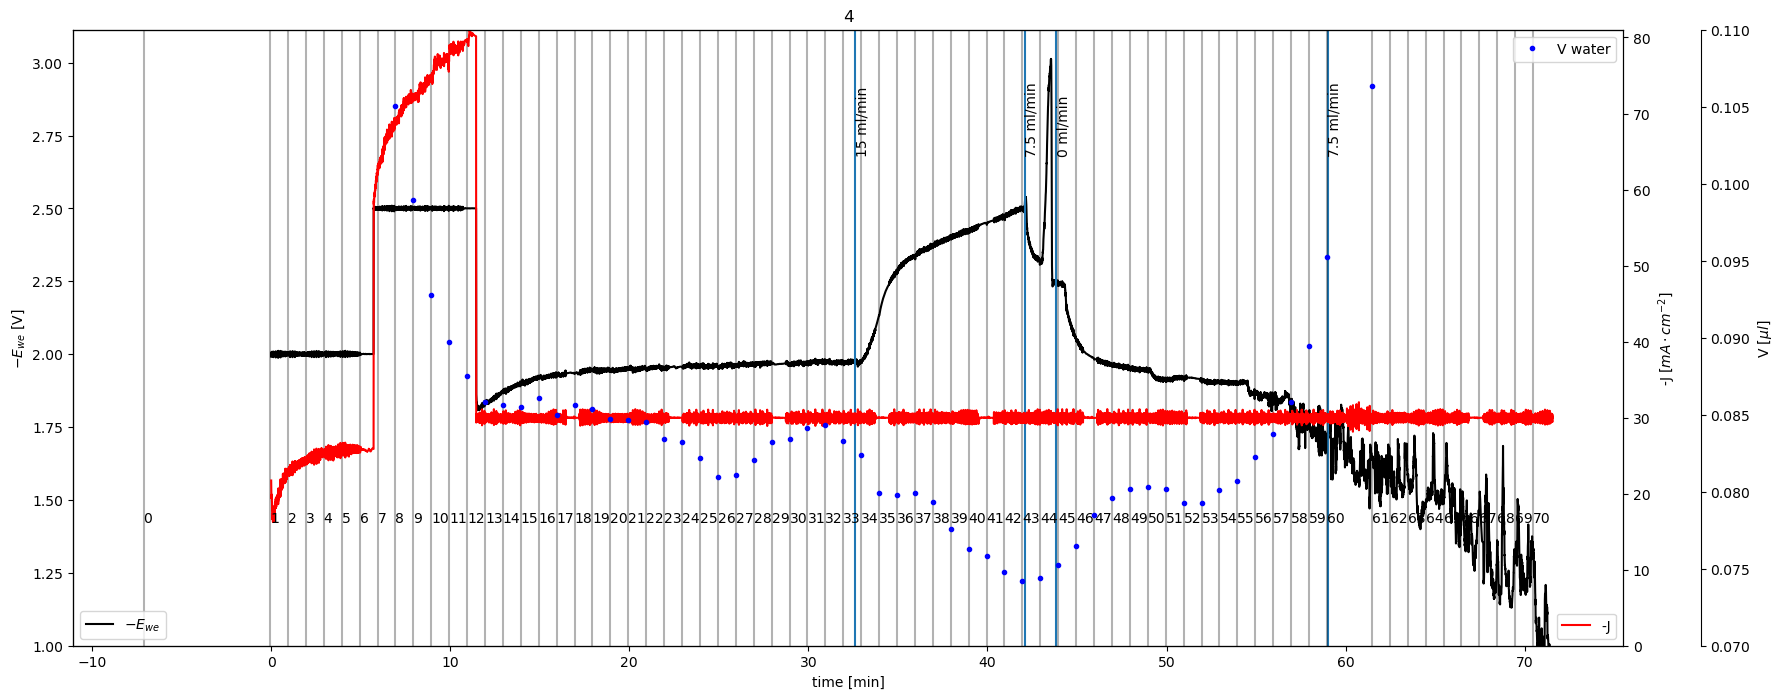

In [42]:
fig, ax = plot_EC_with_annot(sample)
ax3 = ax.twinx()
ax3.plot((t_utc_XTM-t0)/60, watervolumeGDL*px**3*1e9, 'b.', label='V water')
# ax3.plot((t_utc_XTM-t0)/60, watervolumeGDL_old*px**3*1e9, 'g.', label='V water')
ax3.spines.right.set_position(("axes", 1.05))
ax3.set_ylabel('V [$\mu l$]')
ax3.legend()
ax3.set_ylim(0.07,0.11)

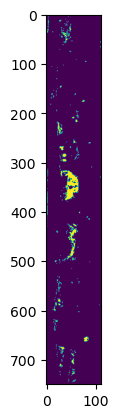

In [88]:
plt.imshow(water[:,230:,100,0])